# 1113 — Unified QCRB engine (replaces the duplicated code in 1104 and 1109)

Protocol (derivation draft, Sec. V.A, eq. 141–150): prepare `S(r)|n>`, drive the signal `D(β)` while dephasing / cooling / heating act, split with the SDF `D(±iα)`, trace out the motion, and take QCRB = 1/QFI of the qubit.

All noise strengths are dimensionless: `Γφt`, `Γct`, `Γht` = rate × exposure time `t_sig`.

What is different from 1104 / 1109:

- **One engine for both notebooks.** The α-sweep plot (1104) and the phase diagram (1109) call the same functions.
- **Exact noise step.** The dissipators never mix different diagonals of ρ, so each time slice applies the exact dephasing + cooling + heating map instead of first-order Kraus operators. Combined with a symmetric (Strang) split against the drive, about `6·Γt` steps are enough, where the old code needed `200·Γt`.
- **Real arithmetic.** For a real drive the motional ρ stays real and symmetric, so all matrices are `Float64`.
- **Exact β-derivative.** `∂ρ/∂β` is propagated alongside ρ, so there is no second "perturbed" run and no finite-difference step.
- **Readout by eq. 149–150.** `C = Tr[D(2iα)ρ]` and the closed-form qubit QFI replace the tensor product, partial trace and eigen-decomposition.
- **No readout-frame shift.** A β-independent shift only multiplies `C` by a constant phase, so it is dropped. (1104's last cell shifted the perturbed state by its own mean, which removed the signal; see the notes at the end.)

In [1]:
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra, Printf
using PyPlot

BLAS.set_num_threads(1)   # 51×51 products are faster single-threaded; parallelism is over sweep points
println("Julia threads: ", Threads.nthreads())

Julia threads: 1


## 1. Closed forms from the derivation

`qcrb_theory` is eq. 33 (no noise), eq. 74 (cooling) and eq. 106 (thermal bath) in one function, written for separate cooling and heating rates: net damping `K = Γct − Γht`, diffusion `(Γct + Γht)(1 − e^{−K})/K`.

In [2]:
function laguerre(n::Int, x::Real)
    n == 0 && return 1.0
    Lm, L = 1.0, 1.0 - x
    for k in 1:(n-1)
        Lm, L = L, ((2k + 1 - x) * L - k * Lm) / (k + 1)
    end
    return L
end

# eq. 33 / 74 / 106. Gc, Gh are Γ_c·t_sig and Γ_h·t_sig. Valid for pure heating too (K < 0).
function qcrb_theory(α::Real, n::Int; r::Real=0.0, Gc::Real=0.0, Gh::Real=0.0)
    K = Gc - Gh
    decay = exp(-K)
    diffusion = abs(K) < 1e-9 ? (Gc + Gh) : (Gc + Gh) * (1 - decay) / K     # (2n̄+1)(1 − e^{−Γt})
    f = abs(K) < 1e-9 ? 1.0 - K / 4 : (2 / K) * (1 - exp(-K / 2))           # laser-drift factor, eq. 71
    B = diffusion + decay * exp(-2r)                                        # B_var, eq. 107
    L = laguerre(n, 4α^2 * decay * exp(-2r))
    return exp(4α^2 * B) / (16α^2 * f^2 * L^2)
end

min_qcrb_theory(n; r=0.0, Gc=0.0, Gh=0.0, αs=0.01:0.002:6.0) =
    minimum(qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs)

# eq. 103 / 117: first-order crossover of states nA and nB, as dimensionless Γ·t_sig
function crossover_first_order(nA::Int, nB::Int; r::Real=0.0, nbar::Real=0.0)
    ys = 0.001:0.001:40.0
    q0(n, y) = exp(y) / (4y * laguerre(n, y)^2)                             # eq. 77 with r = 0
    yA = ys[argmin([q0(nA, y) for y in ys])]; yB = ys[argmin([q0(nB, y) for y in ys])]
    return (log(q0(nB, yB)) - log(q0(nA, yA))) / ((2nbar + 1) * exp(2r) * (yA - yB))
end

# eq. 126 and eq. 139 (dephasing models from the draft; compared with the exact numerics below)
function beta_eff(β::Real, Gphi::Real)
    Gphi < 1e-5 && return β / sqrt(3)
    x = Gphi / 2
    return sqrt(max(0.0, (β^2 / x^2) * (1 + (2 / x) * (exp(-x) - 1) - (1 / (2x)) * (exp(-2x) - 1))))
end
dephasing_K(n::Int) = minimum(1 / (64a^2 * (exp(-2a^2) * laguerre(n, 4a^2))^2) for a in 0.01:0.001:4.0)

println("first-order crossovers Γt (n=1/0, 2/1, 3/2): ", [round(crossover_first_order(n, n - 1), digits=4) for n in 1:3])

first-order crossovers Γt (n=1/0, 2/1, 3/2): [0.2178, 0.071, 0.0409]


## 2. Engine

Cost per sweep point: `steps × (4 real 51×51 products + one O(N³/3) noise update)`, and memory is a handful of 51×51 `Float64` buffers. With dephasing only, the noise update is a single element-wise mask.

In [3]:
const DIM = 51                      # Fock levels 0..50, same cutoff as 1104 / 1109

# exp of the generator in a padded basis, cropped to d×d (removes truncation error on the populated block)
function displace_matrix(ξ::Number, d::Int=DIM; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (improves sensitivity for r > 0)
function squeezed_fock(n::Int, r::Real, d::Int=DIM; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact map of dephasing + cooling + heating over a fraction `frac` of the exposure.
# Element ρ[m, m+k] only couples to ρ[m±1, m±1+k], so there is one small real matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}      # E[k+1] acts on the k-th superdiagonal
    diagonal_only::Bool             # pure dephasing: only the mask is needed
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0                 # <j|a a†|j> with a† cut at N, so the trace is conserved
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

# Everything that depends on the noise point but not on the initial state: build once, reuse for every (n, r).
struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int=DIM)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a                                    # D(β) = exp(βG) is a real rotation for real β
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive (eq. 141). Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)                 # ρ  ← D ρ D'
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)                # dρ ← D dρ D' + [G, ρ]/S
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs; d::Int=DIM) = [displace_matrix(2im * a, d) for a in αs]

# QCRB(α) curve for one state and one noise point. `tail` is the population in the top 5 Fock levels:
# if it is not ≈ 0 the cutoff DIM is too small for that point (this happens for strong heating).
function qcrb_curve(n::Int, αs, Vs; r=0.0, β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, steps=default_steps(Gphi, Gc, Gh))
    ρ, dρ = propagate(squeezed_fock(n, r), Drive(β, Gphi, Gc, Gh; steps=steps))
    return [qcrb_from_state(ρ, dρ, V) for V in Vs], sum(@view ρ[diagind(ρ)[end-4:end]])
end

## 3. Checks against the derivation

Cooling, heating and squeezing have closed forms (eq. 33 / 74 / 106), so the engine can be compared directly. Dephasing has none, so it is checked by doubling the step count.

In [4]:
αs_check = collect(0.05:0.01:2.6)
Vs_check = readout_matrices(αs_check)

println("engine vs closed form (β = 2)")
println("  n    r    Γct   Γht  steps   min QCRB engine   min QCRB theory   rel.diff   α_opt")
for (n, r, Gc, Gh) in ((0, 0.0, 0.0, 0.0), (1, 0.0, 0.0, 0.0), (3, 0.0, 0.0, 0.0), (1, 0.4, 0.0, 0.0), (2, 0.4, 0.3, 0.0),
                       (1, 0.0, 1.0, 0.0), (3, 0.0, 10.0, 0.0), (3, 0.0, 100.0, 0.0), (1, 0.0, 0.5, 0.2), (2, 0.2, 0.0, 0.3))
    q, _ = qcrb_curve(n, αs_check, Vs_check; r=r, Gc=Gc, Gh=Gh)
    th = minimum(qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs_check)
    @printf("  %d  %.1f  %5.1f  %4.1f  %5d   %15.6g   %15.6g   %8.1e   %.2f\n", n, r, Gc, Gh, default_steps(0, Gc, Gh),
            minimum(q), th, abs(minimum(q) - th) / th, αs_check[argmin(q)])
end

println("\ndephasing: default step count vs 16× more steps (β = 2)")
println("  n   Γφt  steps   min QCRB    rel.change")
for (n, G) in ((1, 0.1), (1, 1.0), (3, 1.0), (1, 10.0), (3, 100.0))
    S = default_steps(G, 0, 0)
    q1 = minimum(qcrb_curve(n, αs_check, Vs_check; Gphi=G)[1])
    q2 = minimum(qcrb_curve(n, αs_check, Vs_check; Gphi=G, steps=16S)[1])
    @printf("  %d  %5.1f  %5d   %9.6g   %8.1e\n", n, G, S, q1, abs(q1 - q2) / q2)
end

engine vs closed form (β = 2)
  n    r    Γct   Γht  steps   min QCRB engine   min QCRB theory   rel.diff   α_opt
  0  0.0    0.0   0.0     64           0.67957           0.67957    2.4e-14   0.50
  1  0.0    0.0   0.0     64          0.374884          0.374884    1.8e-14   0.97
  3  0.0    0.0   0.0     64          0.256426          0.256426    3.3e-14   1.63
  1  0.4    0.0   0.0     64          0.168419          0.168419    3.2e-12   1.44
  2  0.4    0.3   0.0     64           1.21108           1.21108    4.6e-07   1.06
  1  0.0    1.0   0.0     64           1.99675           1.99674    5.1e-06   0.36
  3  0.0   10.0   0.0     64            17.234           17.2252    5.1e-04   0.50
  3  0.0  100.0   0.0    600           1699.91           1698.93    5.8e-04   0.50
  1  0.0    0.5   0.2     64           2.39218           2.39218    4.6e-07   0.28
  2  0.2    0.0   0.3     64           1.31714           1.31714    4.6e-07   0.67

dephasing: default step count vs 16× more steps (β = 2)

### Independent check: QuantumOptics master-equation ODE

Same physics as 1104's `master_dynamic` simulation, in dimensionless time (`t ∈ [0, 1]`, drive rate β, jump rates `Γt`). This is the only cell that needs QuantumOptics.

In [5]:
using QuantumOptics

function qcrb_curve_ode(n::Int, αs, Vs; β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, dβ=1e-3)
    b = FockBasis(DIM - 1)
    a = destroy(b); at = create(b); nop = number(b)
    J = typeof(dense(a))[]; rates = Float64[]
    Gphi > 0 && (push!(J, dense(nop)); push!(rates, Gphi))
    Gc > 0 && (push!(J, dense(a)); push!(rates, Gc))
    Gh > 0 && (push!(J, dense(at)); push!(rates, Gh))
    final(βv) = begin
        H = dense(1im * βv * (at - a))
        _, ρt = timeevolution.master([0.0, 1.0], dm(fockstate(b, n)), H, J; rates=rates, reltol=1e-10, abstol=1e-12)
        ρt[end].data
    end
    ρ = final(β); dρ = (final(β + dβ) - final(β - dβ)) / (2dβ)
    out = Float64[]
    for V in Vs
        C = tr(V * ρ); dC = tr(V * dρ)
        push!(out, 1 / (abs2(dC) + real(conj(C) * dC)^2 / (1 - abs2(C))))
    end
    return out
end

println("engine vs QuantumOptics ODE (n = 1, β = 2)")
println("   Γφt   Γct   Γht   min QCRB engine   min QCRB ODE   max rel.diff over α   t_engine   t_ODE")
for (Gp, Gc, Gh) in ((1.0, 0.0, 0.0), (3.0, 0.0, 0.0), (0.0, 0.5, 0.0), (1.0, 0.3, 0.1))
    qcrb_curve(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)
    te = @elapsed qe = qcrb_curve(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)[1]
    to = @elapsed qo = qcrb_curve_ode(1, αs_check, Vs_check; Gphi=Gp, Gc=Gc, Gh=Gh)
    keep = qo .< 1e3
    @printf("  %4.1f  %4.1f  %4.1f   %15.6g   %12.6g   %19.1e   %6.3f s   %5.1f s\n", Gp, Gc, Gh, minimum(qe), minimum(qo),
            maximum(abs.(qe .- qo)[keep] ./ qo[keep]), te, to)
end

engine vs QuantumOptics ODE (n = 1, β = 2)
   Γφt   Γct   Γht   min QCRB engine   min QCRB ODE   max rel.diff over α   t_engine   t_ODE
   1.0   0.0   0.0           1.34845        1.34828               3.7e-04    0.004 s     5.0 s
   3.0   0.0   0.0           5.42664        5.42345               1.8e-03    0.004 s     1.7 s
   0.0   0.5   0.0           2.07488        2.07488               1.4e-05    0.012 s     0.4 s
   1.0   0.3   0.1           3.98036         3.9803               2.8e-04    0.011 s     1.1 s


## 4. QCRB versus readout displacement α (the 1104 plot)

Inputs are dimensionless. To convert 1104's rates in Hz, multiply by `t_sig`; the optional cell below gets `t_sig` from the laser parameters with IonSim.

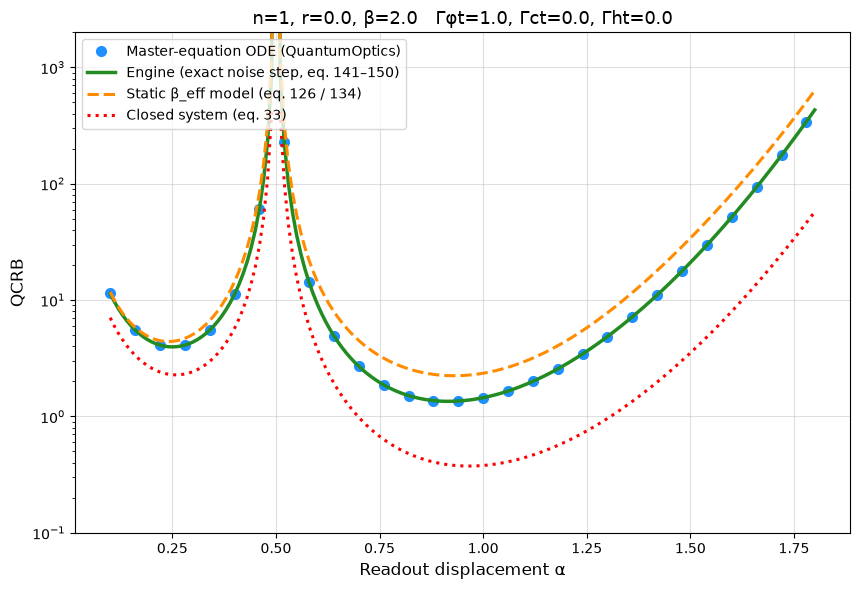

min QCRB = 1.3484 at α = 0.92


In [6]:
function plot_qcrb_vs_alpha(n::Int=1; r=0.0, β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, αs=collect(0.1:0.01:1.8), ode::Bool=true)
    Vs = readout_matrices(αs)
    q, tail = qcrb_curve(n, αs, Vs; r=r, β=β, Gphi=Gphi, Gc=Gc, Gh=Gh)
    tail > 1e-6 && println("warning: $(round(tail, sigdigits=2)) of the population is at the Fock cutoff; raise DIM")

    fig = figure(figsize=(10, 6.5))
    if ode && r == 0
        idx = 1:6:length(αs)
        plot(αs[idx], qcrb_curve_ode(n, αs[idx], Vs[idx]; β=β, Gphi=Gphi, Gc=Gc, Gh=Gh), "o", markersize=7,
             color="dodgerblue", label="Master-equation ODE (QuantumOptics)")
    end
    plot(αs, q, "-", color="forestgreen", linewidth=2.5, label="Engine (exact noise step, eq. 141–150)")
    if Gphi == 0
        plot(αs, [qcrb_theory(a, n; r=r, Gc=Gc, Gh=Gh) for a in αs], "--", color="black", linewidth=1.8, label="Closed form (eq. 74 / 106)")
    elseif Gc == 0 && Gh == 0 && r == 0
        be = beta_eff(β, Gphi); f = (2 / Gphi) * (1 - exp(-Gphi / 2))
        ψ = displace_matrix(be)[:, n+1]
        ρs = (ψ * ψ') .* [exp(-0.5 * Gphi * (i - j)^2) for i in 1:DIM, j in 1:DIM]
        Dm = displace_matrix(-be); ρs = Dm * ρs * Dm'
        plot(αs, [1 / (16a^2 * f^2 * abs2(tr(V * ρs))) for (a, V) in zip(αs, Vs)], "--", color="darkorange", linewidth=2.2,
             label="Static β_eff model (eq. 126 / 134)")
    end
    plot(αs, [qcrb_theory(a, n; r=r) for a in αs], ":", color="red", linewidth=2.2, label="Closed system (eq. 33)")

    yscale("log"); ylim(1e-1, 2e3)
    xlabel("Readout displacement α", fontsize=12); ylabel("QCRB", fontsize=12)
    title("n=$n, r=$r, β=$β   Γφt=$Gphi, Γct=$Gc, Γht=$Gh", fontsize=13)
    legend(fontsize=10, loc="upper left"); grid(alpha=0.4)
    display(fig); close(fig)
    @printf("min QCRB = %.5g at α = %.2f\n", minimum(q), αs[argmin(q)])
    return nothing
end

plot_qcrb_vs_alpha(1; Gphi=1.0)                      # pure dephasing: exact vs the static β_eff model

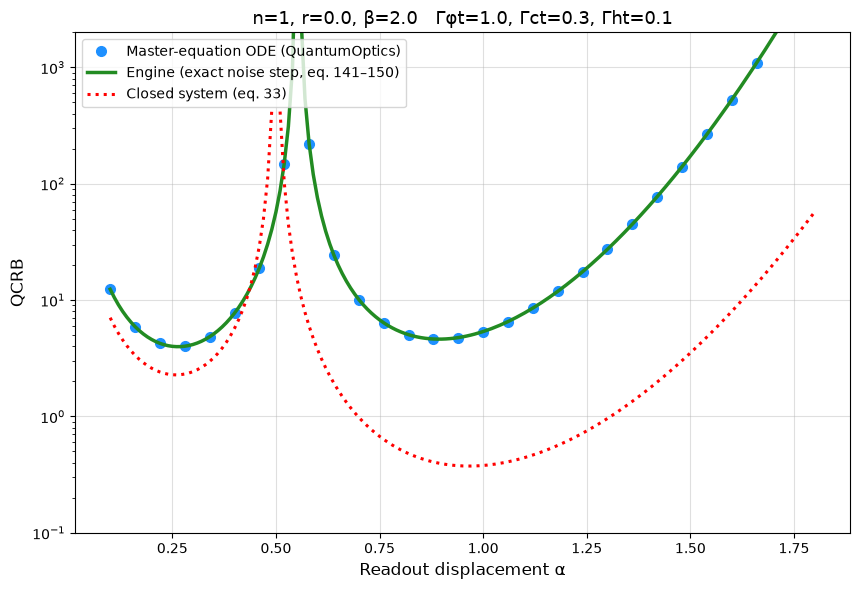

min QCRB = 3.9804 at α = 0.26


In [7]:
plot_qcrb_vs_alpha(1; Gphi=1.0, Gc=0.3, Gh=0.1)      # all three channels at once

In [8]:
# Optional: t_sig from the laser parameters used in 1104 (needs IonSim). Γt = rate[Hz] × t_sig.
try
    @eval using IonSim
    function tsig_seconds(laser_intensity::Float64, β::Float64; trap_freq=19e5)
        hbar = 1.0545718e-34; amu = 1.66053906e-27; m = 39.96259 * amu
        ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
        chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
        chamber = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
        λ = transitionwavelength(ion, ("g", "e"), chamber)
        η = ((2π / λ) / sqrt(2)) * sqrt(hbar / (2 * m * 2π * trap_freq))
        laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=λ)
        Ω = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(laser), wavevector(laser), (; x=0.0, y=0.0, z=1.0)) * 2π
        return 2β / (η * Ω)
    end
    t = Base.invokelatest(tsig_seconds, 1e3, 2.0)
    @printf("t_sig(I = 1e3, β = 2) = %.4g s  →  365 Hz dephasing: Γφt = %.3f;  50 Hz cooling: Γct = %.3f;  10 Hz heating: Γht = %.4f\n",
            t, 365t, 50t, 10t)
catch err
    println("IonSim not available, skipping the Hz → Γt conversion: ", sprint(showerror, err)[1:min(end, 200)])
end

t_sig(I = 1e3, β = 2) = 0.004413 s  →  365 Hz dephasing: Γφt = 1.611;  50 Hz cooling: Γct = 0.221;  10 Hz heating: Γht = 0.0441


## 5. Phase diagram: best QCRB over α versus noise (the 1109 plot)

Black dotted curves are the closed form (shown when there is no dephasing). Grey ticks on the bottom axis are the first-order crossovers of eq. 103. Points where the Fock cutoff is hit are left blank.

100 points × 4 states in 5.2 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.2105
crossover n=2 → n=1 (r=0.0) at Γt = 0.0696
crossover n=2 → n=1 (r=0.0) at Γt = 0.4652
crossover n=2 → n=1 (r=0.0) at Γt = 0.5174
crossover n=3 → n=2 (r=0.0) at Γt = 0.0404
crossover n=3 → n=2 (r=0.0) at Γt = 0.6096
crossover n=3 → n=2 (r=0.0) at Γt = 0.7351


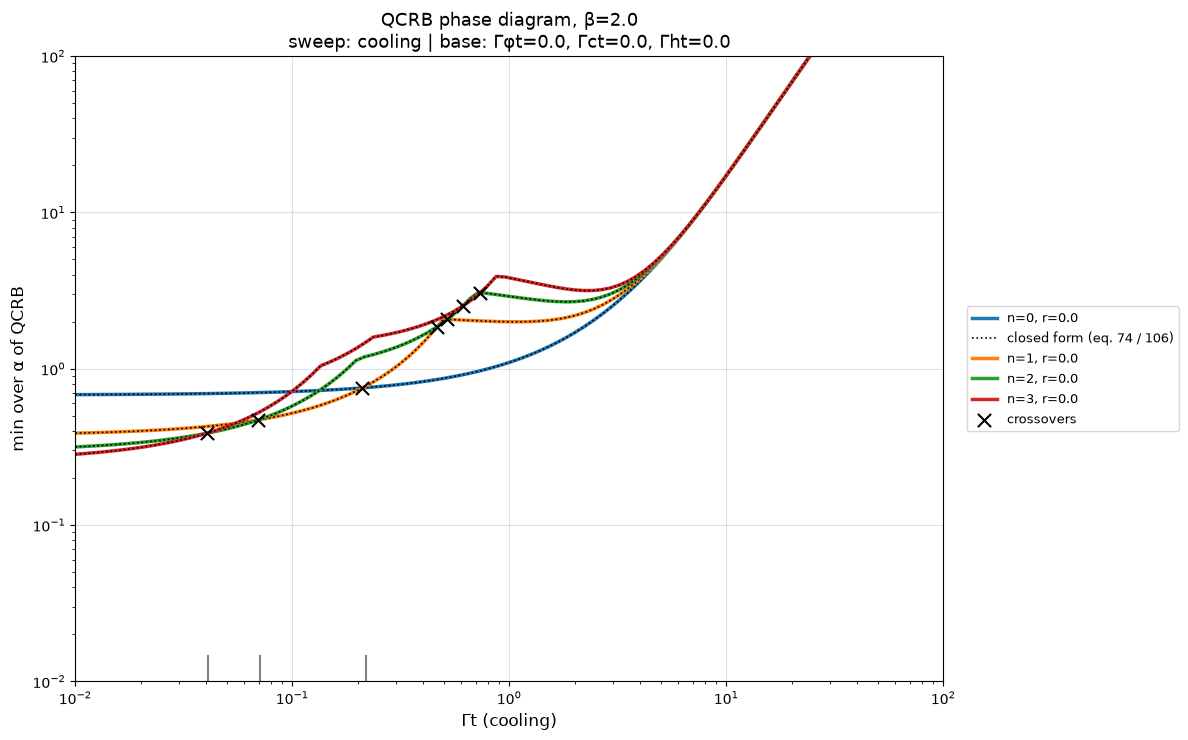

In [9]:
function crossings(x, y1, y2)
    out = Tuple{Float64,Float64}[]
    for k in 1:(length(x)-1)
        d1 = y1[k] - y2[k]; d2 = y1[k+1] - y2[k+1]
        (isfinite(d1) && isfinite(d2) && d1 * d2 < 0) || continue
        abs(d1) + abs(d2) < 1e-3 * (y1[k] + y2[k]) && continue        # merged curves, not a real crossing
        t = d1 / (d1 - d2)
        push!(out, (10.0^((1 - t) * log10(x[k]) + t * log10(x[k+1])), 10.0^((1 - t) * log10(y1[k]) + t * log10(y1[k+1]))))
    end
    return out
end

function plot_phase_diagram(; sweep::Symbol=:cooling, β::Float64=2.0, n_vals=[0, 1, 2, 3], r_vals=[0.0],
                            base=(dephasing=0.0, cooling=0.0, heating=0.0), g_range=(1e-2, 1e2), npts::Int=100)
    gs = 10.0 .^ range(log10(g_range[1]), log10(g_range[2]), length=npts)
    αs = collect(0.05:0.01:(2.6 * exp(maximum(r_vals))))            # grid widens with squeezing (α_opt ∝ e^r)
    Vs = readout_matrices(αs)
    states = [(n, r) for n in n_vals for r in r_vals]
    ψs = Dict(s => squeezed_fock(s[1], s[2]) for s in states)
    best = Dict(s => fill(NaN, npts) for s in states)
    αopt = Dict(s => fill(NaN, npts) for s in states)
    rates(g) = (sweep == :dephasing ? g : base.dephasing, sweep == :cooling ? g : base.cooling, sweep == :heating ? g : base.heating)

    elapsed = @elapsed Threads.@threads for i in 1:npts
        Gp, Gc, Gh = rates(gs[i])
        drv = Drive(β, Gp, Gc, Gh)                                  # shared by every (n, r) at this noise point
        for s in states
            ρ, dρ = propagate(ψs[s], drv)
            sum(@view ρ[diagind(ρ)[end-4:end]]) > 1e-6 && continue  # Fock cutoff reached: leave NaN
            q = [qcrb_from_state(ρ, dρ, V) for V in Vs]
            k = argmin(q); best[s][i] = q[k]; αopt[s][i] = αs[k]
        end
    end
    @printf("%d points × %d states in %.1f s\n", npts, length(states), elapsed)
    for s in states
        nbad = count(isnan, best[s]); nedge = count(==(αs[end]), αopt[s])
        nbad > 0 && println("n=$(s[1]), r=$(s[2]): $nbad points dropped (population reached the Fock cutoff)")
        nedge > 0 && println("n=$(s[1]), r=$(s[2]): α_opt sits on the grid edge at $nedge points")
    end

    fig = figure(figsize=(12, 7.5))
    styles = ["-", "--", ":", "-."]
    no_dephasing = sweep != :dephasing && base.dephasing == 0
    for s in states
        n, r = s
        plot(gs, best[s], color="C$(findfirst(==(n), n_vals) - 1)", linestyle=styles[findfirst(==(r), r_vals)], linewidth=2.5, label="n=$n, r=$r")
        if no_dephasing
            plot(gs, [min_qcrb_theory(n; r=r, Gc=rates(g)[2], Gh=rates(g)[3], αs=αs) for g in gs], ":", color="black", linewidth=1.2,
                 label=(s == states[1] ? "closed form (eq. 74 / 106)" : nothing))
        end
    end
    cx = Float64[]; cy = Float64[]
    for r in r_vals, (nlo, nhi) in zip(n_vals[1:end-1], n_vals[2:end])
        for (x, y) in crossings(gs, best[(nhi, r)], best[(nlo, r)])
            push!(cx, x); push!(cy, y)
            @printf("crossover n=%d → n=%d (r=%.1f) at Γt = %.4f\n", nhi, nlo, r, x)
        end
    end
    isempty(cx) || scatter(cx, cy, color="black", s=90, zorder=5, marker="x", label="crossovers")
    if sweep == :cooling && base.heating == 0 && base.dephasing == 0
        for r in r_vals, n in n_vals[2:end]
            axvline(crossover_first_order(n, n - 1; r=r), ymax=0.04, color="grey", linewidth=1.5)
        end
    end
    xscale("log"); yscale("log"); xlim(g_range...); ylim(1e-2, 1e2)
    xlabel("Γt ($(sweep))", fontsize=12); ylabel("min over α of QCRB", fontsize=12)
    title("QCRB phase diagram, β=$β\nsweep: $(sweep) | base: Γφt=$(base.dephasing), Γct=$(base.cooling), Γht=$(base.heating)", fontsize=13)
    grid(alpha=0.4); legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5)); tight_layout()
    display(fig); close(fig)
    return (gs=gs, best=best, αopt=αopt)
end

res_cool = plot_phase_diagram(sweep=:cooling);

100 points × 4 states in 2.1 s
crossover n=1 → n=0 (r=0.0) at Γt = 1.1337
crossover n=1 → n=0 (r=0.0) at Γt = 41.4056
crossover n=2 → n=1 (r=0.0) at Γt = 0.4743
crossover n=2 → n=1 (r=0.0) at Γt = 10.9979
crossover n=2 → n=1 (r=0.0) at Γt = 26.5980
crossover n=3 → n=2 (r=0.0) at Γt = 0.3367
crossover n=3 → n=2 (r=0.0) at Γt = 3.7253
crossover n=3 → n=2 (r=0.0) at Γt = 15.0839


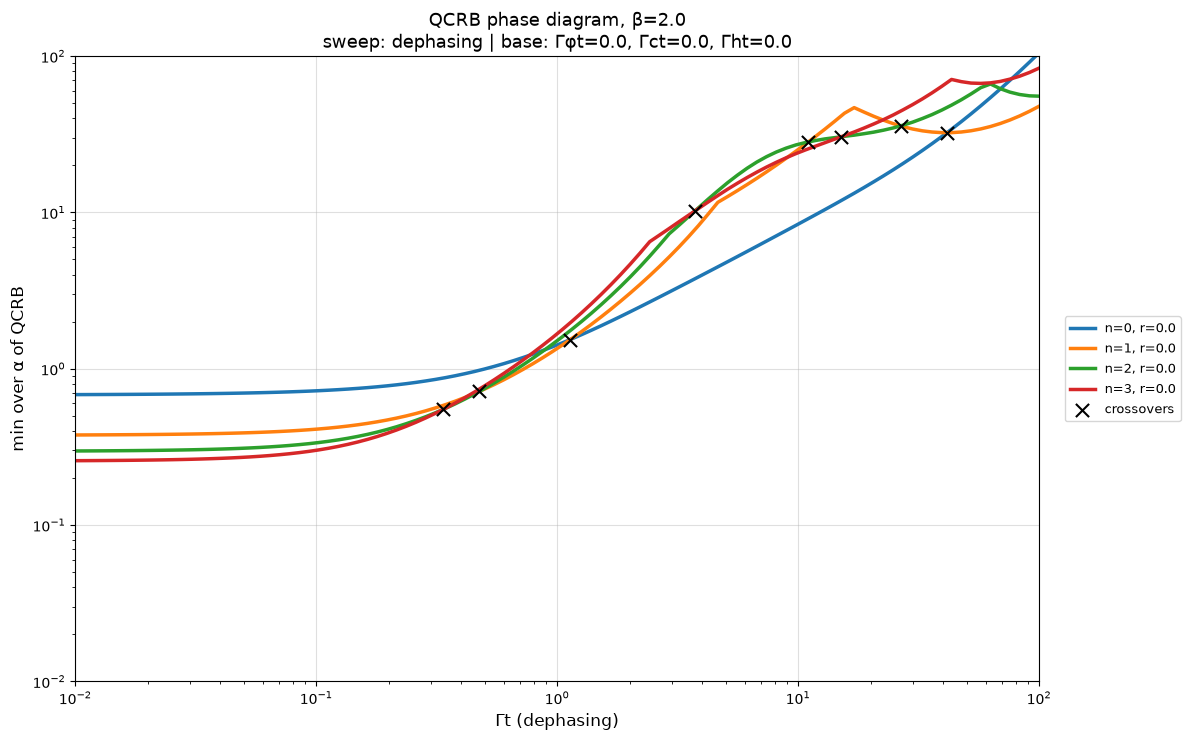

In [10]:
res_deph = plot_phase_diagram(sweep=:dephasing);

100 points × 4 states in 3.3 s
n=0, r=0.0: 37 points dropped (population reached the Fock cutoff)
n=1, r=0.0: 40 points dropped (population reached the Fock cutoff)
n=2, r=0.0: 43 points dropped (population reached the Fock cutoff)
n=3, r=0.0: 45 points dropped (population reached the Fock cutoff)
crossover n=1 → n=0 (r=0.0) at Γt = 0.2675
crossover n=2 → n=1 (r=0.0) at Γt = 0.0750
crossover n=3 → n=2 (r=0.0) at Γt = 0.0421


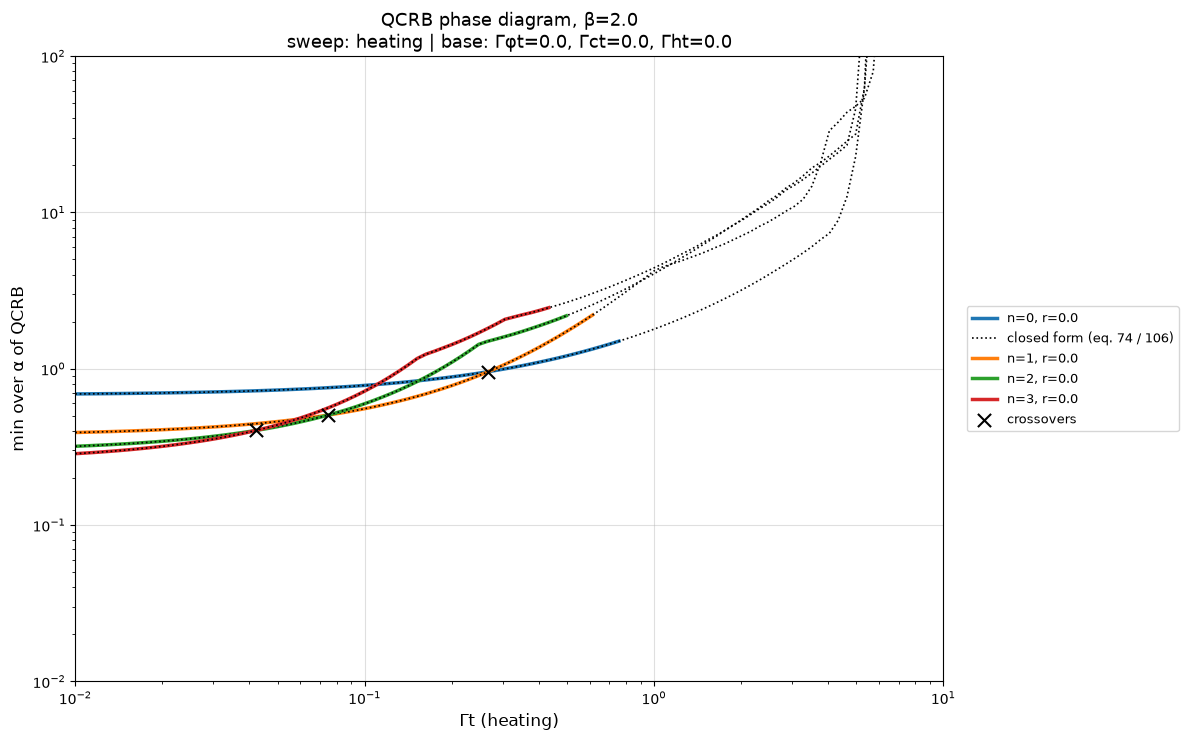

In [11]:
res_heat = plot_phase_diagram(sweep=:heating, g_range=(1e-2, 1e1));

100 points × 6 states in 7.9 s
crossover n=1 → n=0 (r=0.0) at Γt = 0.2105
crossover n=2 → n=1 (r=0.0) at Γt = 0.0696
crossover n=2 → n=1 (r=0.0) at Γt = 0.4652
crossover n=2 → n=1 (r=0.0) at Γt = 0.5174
crossover n=1 → n=0 (r=0.4) at Γt = 0.1001
crossover n=2 → n=1 (r=0.4) at Γt = 0.0319
crossover n=2 → n=1 (r=0.4) at Γt = 0.2356
crossover n=2 → n=1 (r=0.4) at Γt = 0.2660


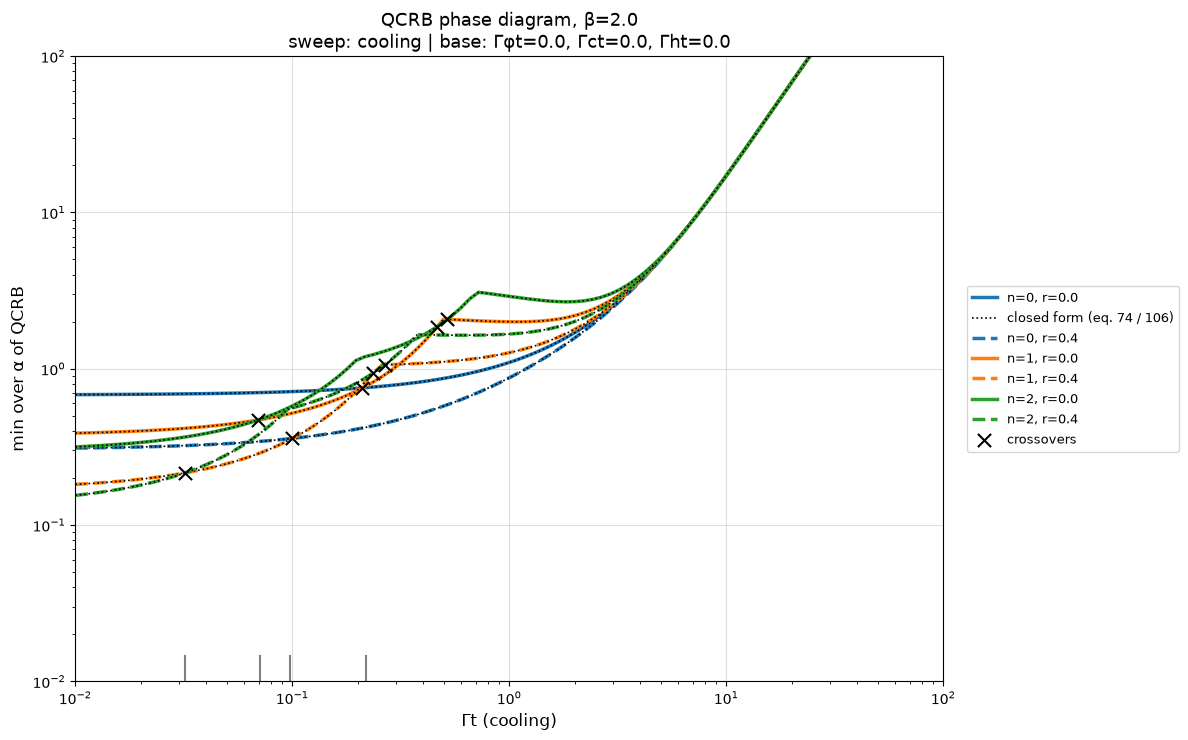

In [12]:
res_sq = plot_phase_diagram(sweep=:cooling, n_vals=[0, 1, 2], r_vals=[0.0, 0.4]);

## 6. Strong dephasing: numerics versus eq. 139

Eq. 139 predicts `min QCRB → K_n (Γφt)²` with a state-dependent constant `K_n` that does not depend on β. The table shows `min QCRB / (Γφt)²` from the engine.

In [13]:
αs_wide = collect(0.05:0.01:3.5); Vs_wide = readout_matrices(αs_wide)
println("eq. 139 K_n, n = 0..3:              ", join([@sprintf("%.4f", dephasing_K(n)) for n in 0:3], "  "))
for β in (0.1, 1.0, 2.0), G in (100.0, 1000.0)
    drv = Drive(β, G, 0.0, 0.0)
    vals = Float64[]; edge = false
    for n in 0:3
        ρ, dρ = propagate(squeezed_fock(n, 0.0), drv)
        q = [qcrb_from_state(ρ, dρ, V) for V in Vs_wide]
        push!(vals, minimum(q) / G^2); edge |= argmin(q) == length(αs_wide)
    end
    @printf("engine  β = %.1f, Γφt = %6.0f:      %s%s\n", β, G, join([@sprintf("%.4f", v) for v in vals], "  "), edge ? "   (α_opt on grid edge)" : "")
end

eq. 139 K_n, n = 0..3:              0.1699  0.0937  0.0740  0.0641
engine  β = 0.1, Γφt =    100:      0.1606  0.0803  0.0572  0.0450
engine  β = 0.1, Γφt =   1000:      0.1599  0.0793  0.0561  0.0438
engine  β = 1.0, Γφt =    100:      0.0261  0.0071  0.0043  0.0034
engine  β = 1.0, Γφt =   1000:      0.0218  0.0049  0.0023  0.0015
engine  β = 2.0, Γφt =    100:      0.0105  0.0048  0.0055  0.0084
engine  β = 2.0, Γφt =   1000:      0.0063  0.0014  0.0007  0.0005


## Notes

**Why 1104 showed no plot.** Its saved outputs are errors from an older environment: `matplotlib` could not be imported (PyCall pointed at `/usr/bin/python3`) and `IonSim` was not in the project, so every later cell failed with `UndefVarError`. Both are fixed in the current environment. The last cell (the "ultra-fast" phase diagram) was never run; when run it draws an empty frame, because it shifts the perturbed state by its *own* mean displacement, which removes the signal phase and sends every QCRB above the plotted range.

**Where the code and the derivation differ.**

- Cooling, heating and squeezing: the engine reproduces eq. 33 / 74 / 106 (table in Sec. 3).
- Dephasing, moderate noise: the static β_eff model (eq. 126 / 134) is above the exact result once `Γφt ≳ 0.3` (first plot in Sec. 4).
- Dephasing, strong noise: the `(Γφt)²` scaling of eq. 139 holds, but the constant depends on β and is below `K_n` (Sec. 6).
- Heating sweeps: without cooling the phonon number grows like `e^{Γht}`, so with β = 2 the 51 Fock levels are only enough up to `Γht ≈ 0.5`. Points beyond that are dropped instead of plotted; the closed form (dotted) continues.
- The exact crossovers are slightly below the first-order values of eq. 103 (0.211 / 0.070 / 0.040 against 0.218 / 0.071 / 0.041).